# WP-4 — Aday kod inceleme (candidate inspection)

**Amac (toplanti notlarindan):**

1. Girise **bozuk** bir maske verildiginde, her latent pozisyonu icin en yakin **5 kodu** sec ve her birinin **ciktisini AYRI AYRI** goster (ortalama ALMADAN).
2. Bu 5 adayin **uzakliklarini** yaz ve grafikte goster: uzaklik profili **lineer mi, exponansiyel mi**?
3. Bu profil **her ornek icin ayni mi**, yoksa yalnizca **buyuk kesitler** icin mi boyle?
4. Bir fonksiyon ile ilk-5 degil, **herhangi bir sirali kod**a (rank 0, 10, 100, 500...) erisebilelim.
5. **SDF Dice**: temiz referans maske ile SDF modelinin tahmini arasindaki Dice skorunu olc.

Bu defter SADECE cikarim (inference) yapar; hicbir sey egitmez, mevcut hicbir dosyayi degistirmez. Egitilmis taban VQ-VAE'nin (`vae3d_vqvae_best.pt`) kendi kod defterini (codebook) kullanir.

> Calistirma ortami: CUDA'li `sam2` conda ortami (CPU `python` degil).

## 0) Kurulum — importlar, yol ayari, config, cihaz, model

In [6]:
import sys
from pathlib import Path

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

# proje kokunu ve scripts/ yolunu ekle (script'lerdeki gibi)
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
for p in (PROJECT_ROOT, PROJECT_ROOT / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from data import load_config
from train import resolve_device, set_seed
import evaluate_correlation_3d as ev3d
from evaluate_correlation_3d_vq import load_model

EPS = 1e-6
print("proje kok:", PROJECT_ROOT)

proje kok: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality


In [7]:
config = load_config(str(PROJECT_ROOT / "configs" / "vae3d_vq.yaml"))
device = resolve_device(str(config["train"]["device"]))
CKPT = PROJECT_ROOT / "outputs" / "checkpoints" / "vae3d_vqvae_best.pt"
model = load_model(CKPT, device)
model.eval()
print("cihaz:", device)
print("codebook:", tuple(model.quantizer.embedding.weight.shape), "(K x D)")

cihaz: cuda
codebook: (512, 64) (K x D)


## 1) Cekirdek yardimci fonksiyonlar

`multi_candidate_wp4.py:consensus_and_uncertainty` mantigini burada **rank secilebilir** hale getiriyoruz:

* `encode_and_distances(x)` — hacmi P=4x4x4=64 pozisyona kodlar, her pozisyonun **tum K koda** olan L2 uzakliklarini dondurur.
* `candidate_by_ranks(x, ranks)` — istenen **rank listesi** (0=en yakin) icin her pozisyonda o sirali kodu secer, decode eder; her adayin olasilik haritasi + ortalama uzakligini dondurur.
* `distance_profile(x)` — her rank icin (0..K-1) pozisyonlar uzerinden **ortalama uzakligi** dondurur (lineer/exponansiyel testi icin).
* `dice(a, b)` — ikili Dice.

In [8]:
@torch.no_grad()
def encode_and_distances(model, x):
    """x: (1,1,64,64,64) -> (z (1,P,D), dist (1,P,K), shape (b,D,d,h,w))."""
    z_e, _ = model._encode_features(x)                     # (1,D,d,h,w)
    b, D, d, h, w = z_e.shape
    z = z_e.permute(0, 2, 3, 4, 1).contiguous().view(b, -1, D)   # (1,P,D)
    W = model.quantizer.embedding.weight                    # (K,D)
    dist = z.pow(2).sum(-1, keepdim=True) - 2.0 * z @ W.t() + W.pow(2).sum(1)
    return z, dist.clamp_min(0.0), (b, D, d, h, w)


@torch.no_grad()
def candidate_by_ranks(model, x, ranks):
    """Verilen rank listesi icin her adayi AYRI decode et.
    Dondurur: {rank: (prob_map (64,64,64) np, mean_dist float)}, K."""
    z, dist, (b, D, d, h, w) = encode_and_distances(model, x)
    K = dist.shape[-1]
    order = torch.argsort(dist, dim=-1)                     # (1,P,K) artan
    out = {}
    for r in ranks:
        idx = order[..., r]                                # (1,P) o rank'taki kod indexi
        d_r = torch.gather(dist, -1, idx.unsqueeze(-1)).squeeze(-1).mean().item()
        z_q_flat = model.quantizer.embedding(idx)          # (1,P,D)
        z_q = z_q_flat.view(b, d, h, w, D).permute(0, 4, 1, 2, 3).contiguous()
        prob = torch.sigmoid(model._decode_features(z_q, feats=[]))[0, 0].cpu().numpy()
        out[r] = (prob, d_r)
    return out, K


@torch.no_grad()
def distance_profile(model, x):
    """Her rank icin pozisyonlar uzerinden ortalama uzaklik: (K,) np."""
    _, dist, _ = encode_and_distances(model, x)
    sorted_d, _ = torch.sort(dist, dim=-1)                  # (1,P,K)
    return sorted_d.mean(dim=1)[0].cpu().numpy()            # (K,)


def dice(a, b):
    a = a > 0.5; b = b > 0.5
    inter = np.logical_and(a, b).sum()
    return float(2.0 * inter / (a.sum() + b.sum() + EPS))


def to_x(mask_np):
    """(64,64,64) np ikili maske -> (1,1,64,64,64) tensor (cihazda)."""
    return torch.from_numpy(mask_np.astype(np.float32))[None, None].to(device)

## 2) Bir bozuk ornek sec (+ temiz referansi)

`evaluate_correlation_3d`'nin degradasyon protokolunu aynen kullaniyoruz: temiz hacimler + sentetik bozmalar. Blok yapisi: her temiz maskeyi `n_per_mask` bozma izler, yani `block = 1 + n_per_mask`. Bozuk ornek `gi`'nin temiz referansi `masks[(gi//block)*block]`.

In [9]:
set_seed(42)
clean = ev3d.load_clean_volumes(config, "test", limit=20, seed=42)
degrader = ev3d.calibrate_degrader(config, clean, 42)
masks, true_dice, is_clean = ev3d.build_eval_set(clean, degrader, n_per_mask=2, seed=42)
block = 1 + 2

# ilk bozuk ornegi sec (gi=1); referansi bloktaki temiz maske (gi=0)
gi = 1
ref = masks[(gi // block) * block]        # temiz ground-truth
inp = masks[gi]                            # bozuk girdi
print(f"secilen bozuk ornek gi={gi} | true Dice(bozuk, temiz) = {true_dice[gi]:.3f}")
print(f"referans voxel = {int(ref.sum())} | bozuk voxel = {int(inp.sum())}")

secilen bozuk ornek gi=1 | true Dice(bozuk, temiz) = 0.861
referans voxel = 50778 | bozuk voxel = 67143


## 3) En yakin 5 adayin ciktilari — AYRI AYRI (ortalama YOK)

Her adayin orta-eksenel kesiti + kendi ortalama uzakligi (`d_r`). En saga karsilastirma icin **bozuk girdi** ve **temiz referans** eklendi. Baslikta her adayin referansa Dice'i de var.

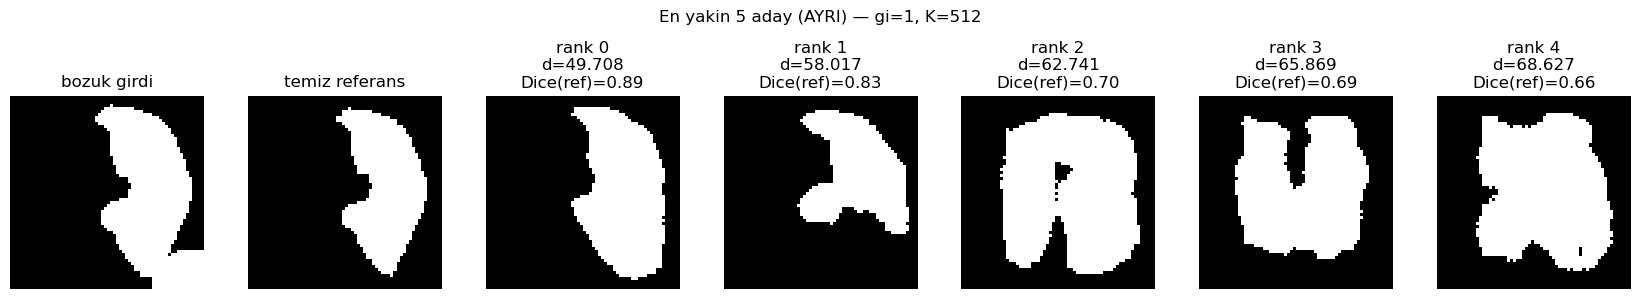

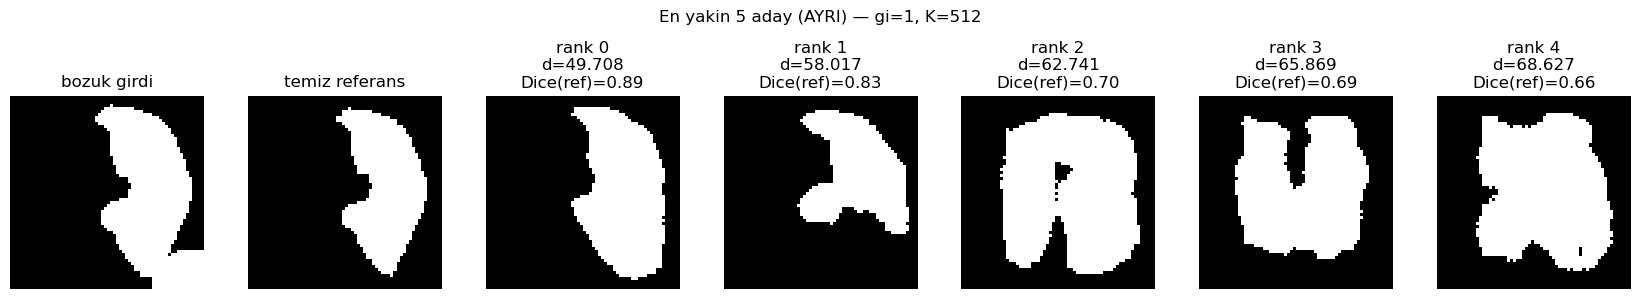

Dice(aday0, aday1) = 0.813
Dice(aday0, aday2) = 0.731
Dice(aday0, aday3) = 0.715
Dice(aday0, aday4) = 0.681


In [10]:
x = to_x(inp)
cands, K = candidate_by_ranks(model, x, ranks=[0, 1, 2, 3, 4])
zc = inp.shape[0] // 2  # orta eksenel kesit

cols = 5 + 2
fig, axes = plt.subplots(1, cols, figsize=(2.4 * cols, 2.8))
axes[0].imshow(inp[zc], cmap="gray"); axes[0].set_title("bozuk girdi")
axes[1].imshow(ref[zc], cmap="gray"); axes[1].set_title("temiz referans")
for i, r in enumerate([0, 1, 2, 3, 4]):
    prob, d_r = cands[r]
    m = (prob > 0.5).astype(np.float32)
    ax = axes[2 + i]
    ax.imshow(m[zc], cmap="gray")
    ax.set_title(f"rank {r}\nd={d_r:.3f}\nDice(ref)={dice(m, ref):.2f}")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"En yakin 5 aday (AYRI) — gi={gi}, K={K}", y=1.05)
fig.tight_layout()
plt.show()

# adaylar birbirinden farkli mi? (aday-aday Dice)
m0 = (cands[0][0] > 0.5)
for r in [1, 2, 3, 4]:
    mr = (cands[r][0] > 0.5)
    print(f"Dice(aday0, aday{r}) = {dice(m0.astype(float), mr.astype(float)):.3f}")

## 4) Uzaklik profili — lineer mi, exponansiyel mi?

Solda ilk k=5 rank; sagda tum K rank (log-eksende: exponansiyel ise log'da duz cizgi olur). Log-farklarin (ardisik rank artis orani) sabitligi exponansiyele, uzakligin kendisinin sabit artmasi lineere isaret eder.

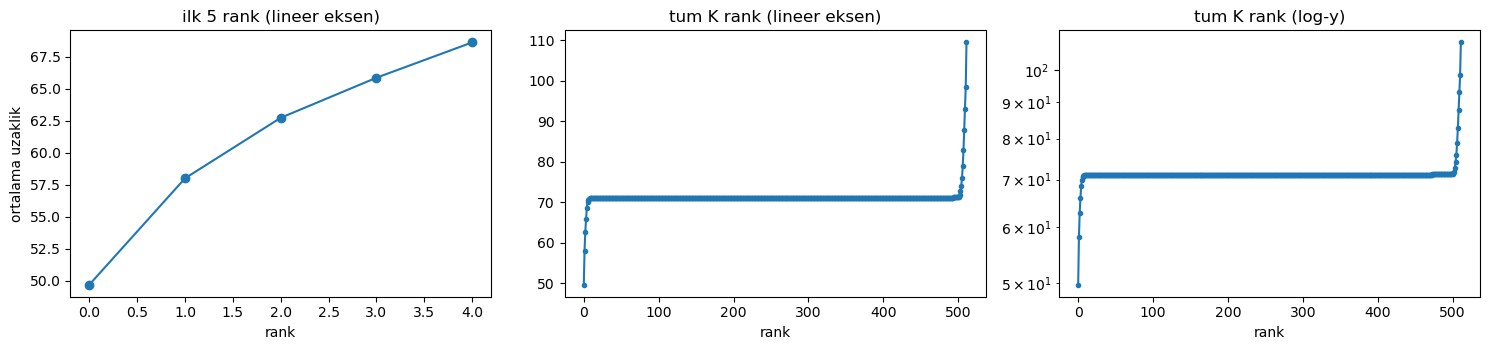

ardisik FARK (rank0->4): [8.3095 4.7237 3.1284 2.7574]
ardisik ORAN (rank0->4): [1.167 1.081 1.05  1.042]


In [11]:
prof = distance_profile(model, x)    # (K,)
k5 = np.arange(5)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(k5, prof[:5], "o-"); ax[0].set_title("ilk 5 rank (lineer eksen)")
ax[0].set_xlabel("rank"); ax[0].set_ylabel("ortalama uzaklik")
ax[1].plot(np.arange(K), prof, ".-"); ax[1].set_title("tum K rank (lineer eksen)")
ax[1].set_xlabel("rank")
ax[2].semilogy(np.arange(K), prof + EPS, ".-"); ax[2].set_title("tum K rank (log-y)")
ax[2].set_xlabel("rank")
fig.tight_layout(); plt.show()

# ilk 5 icin ardisik artis: lineer -> fark sabit; exponansiyel -> oran sabit
diffs = np.diff(prof[:5])
ratios = prof[1:5] / (prof[:4] + EPS)
print("ardisik FARK (rank0->4):", np.round(diffs, 4))
print("ardisik ORAN (rank0->4):", np.round(ratios, 3))

## 5) Her ornek icin ayni mi? Buyuk vs kucuk kesit

Birden fazla bozuk hacmin profilini ust uste ciziyoruz ve her birinin **hacim buyuklugunu** (voxel sayisi = 'kesit buyuklugu' vekili) etiketliyoruz. Boylece profilin ornekten ornege / buyuk-kucuk yapidan degisip degismedigini gorurruz.

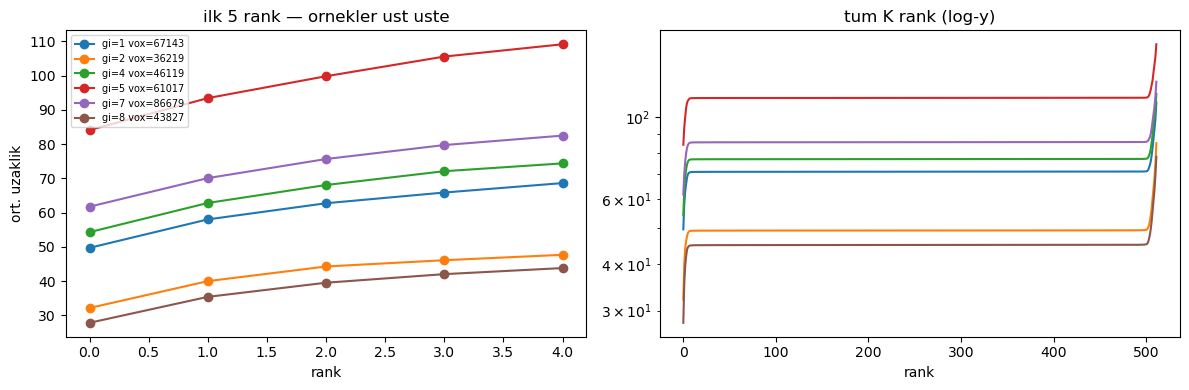

gi | voxel | d(rank0) | d(rank4)
  2 |  36219 | 32.1369 | 47.6732
  8 |  43827 | 27.8135 | 43.8033
  4 |  46119 | 54.2973 | 74.3818
  5 |  61017 | 84.1144 | 109.1800
  1 |  67143 | 49.7077 | 68.6266
  7 |  86679 | 61.7380 | 82.4970


In [12]:
# birkac bozuk ornek topla (farkli hastalar/bloklar)
deg_indices = [i for i in range(len(masks)) if not is_clean[i]]
sample = deg_indices[:6]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
profiles = []
for i in sample:
    p = distance_profile(model, to_x(masks[i]))
    profiles.append((i, int(masks[i].sum()), p))
    ax[0].plot(np.arange(5), p[:5], "o-", label=f"gi={i} vox={int(masks[i].sum())}")
    ax[1].semilogy(np.arange(K), p + EPS, "-", label=f"gi={i}")
ax[0].set_title("ilk 5 rank — ornekler ust uste"); ax[0].set_xlabel("rank"); ax[0].set_ylabel("ort. uzaklik")
ax[0].legend(fontsize=7)
ax[1].set_title("tum K rank (log-y)"); ax[1].set_xlabel("rank")
fig.tight_layout(); plt.show()

# buyukluk ile ilk uzaklik iliskisi
print("gi | voxel | d(rank0) | d(rank4)")
for i, vox, p in sorted(profiles, key=lambda t: t[1]):
    print(f"{i:3d} | {vox:6d} | {p[0]:.4f} | {p[4]:.4f}")

## 6) Herhangi bir rank'a erisim (ilk-5 degil)

`candidate_by_ranks` zaten herhangi rank'i kabul ediyor. Uzak rank'lara (10, 100, K-1) gidildikce ciktinin referanstan uzaklasmasini (Dice dususu) gozlemleyelim — kod defterinin 'ne kadar farkli sekiller uretebildigini' gosterir.

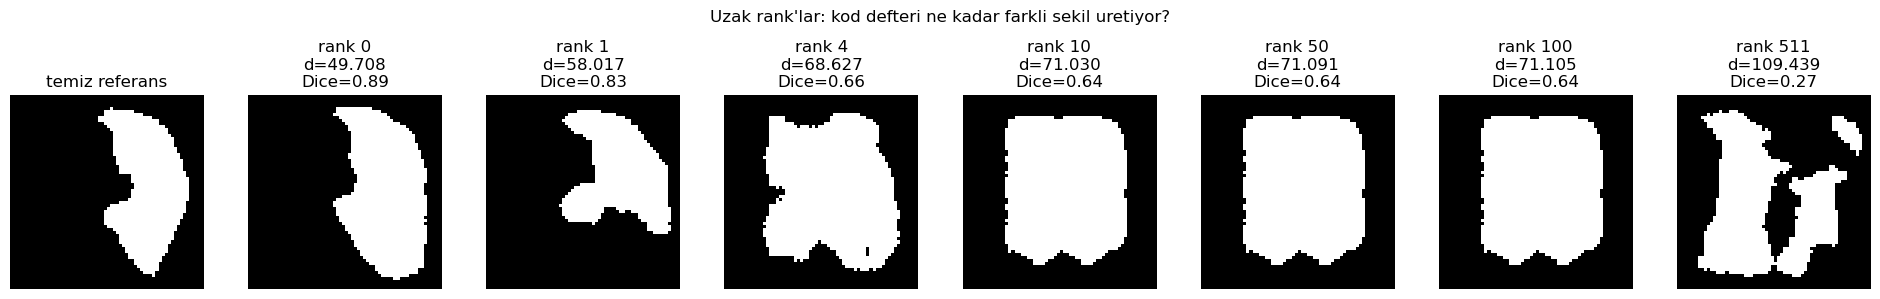

In [13]:
far_ranks = [0, 1, 4, 10, 50, 100, K - 1]
far_ranks = [r for r in far_ranks if r < K]
cands_far, _ = candidate_by_ranks(model, x, ranks=far_ranks)

cols = len(far_ranks) + 1
fig, axes = plt.subplots(1, cols, figsize=(2.4 * cols, 2.8))
axes[0].imshow(ref[zc], cmap="gray"); axes[0].set_title("temiz referans"); axes[0].axis("off")
for i, r in enumerate(far_ranks):
    prob, d_r = cands_far[r]
    m = (prob > 0.5).astype(np.float32)
    ax = axes[1 + i]
    ax.imshow(m[zc], cmap="gray")
    ax.set_title(f"rank {r}\nd={d_r:.3f}\nDice={dice(m, ref):.2f}")
    ax.axis("off")
fig.suptitle("Uzak rank'lar: kod defteri ne kadar farkli sekil uretiyor?", y=1.05)
fig.tight_layout(); plt.show()

## 6.5) Secili rank'lardan uncertainty (entropi) haritasi

WP-4 figuru ilk-5 adayi kullaniyordu; burada **sen** rank kumesini seciyorsun (`SEL_RANKS`, or. `[0,1,2]` veya `[0,2,5]`). `consensus_from_ranks` bu adaylarin uzaklik-agirlikli ortalamasini (konsensus P) ve ikili entropisini H(P) uretir.

Figur: istedigin sayida (`N_ROWS`) **rastgele** karaciger ornegi alt alta; her satirda sirayla **bozuk girdi | temiz referans | secili adaylar (tek tek) | konsensus (P>0.5, 'ortalama') | entropi H(P)**. Sol etikette `D`=true Dice, `H`=ortalama entropi.

Yorum: az/yakin aday secince adaylar ayni -> entropi ~0 (koyu). Uzak rank ekledikce adaylar ayrisir -> entropi buyur (parlak) = model o bolgede kararsiz.

In [14]:
@torch.no_grad()
def consensus_from_ranks(model, x, ranks):
    """Secili rank kumesinden uzaklik-agirlikli konsensus + entropi (b=1).
    Dondurur: P (X,Y,Z), entropy (X,Y,Z), per-cand prob listesi, agirliklar cw (R,).

    Agirlik w_r = (1/d_r) / sum_j(1/d_j) — WP-4 ile ayni, ama ilk-5 yerine
    'ranks' listesindeki adaylar uzerinden. Entropi = ikili H(P) (nat)."""
    z, dist, (b, D, d, h, w) = encode_and_distances(model, x)
    order = torch.argsort(dist, dim=-1)
    probs, d_rs = [], []
    for r in ranks:
        idx = order[..., r]
        d_r = torch.gather(dist, -1, idx.unsqueeze(-1)).squeeze(-1).mean(dim=1)   # (b,)
        z_q = model.quantizer.embedding(idx).view(b, d, h, w, D).permute(0, 4, 1, 2, 3).contiguous()
        p_r = torch.sigmoid(model._decode_features(z_q, feats=[]))[:, 0]          # (b,X,Y,Z)
        probs.append(p_r); d_rs.append(d_r)
    d_stack = torch.stack(d_rs, dim=1) + EPS        # (b,R)
    cw = 1.0 / d_stack
    cw = cw / cw.sum(dim=1, keepdim=True)           # (b,R) aday agirliklari
    P = None
    for i, p_r in enumerate(probs):
        wr = cw[:, i].view(b, 1, 1, 1)
        P = p_r * wr if P is None else P + p_r * wr
    P = P.clamp(EPS, 1.0 - EPS)
    ent = -(P * P.log() + (1.0 - P) * (1.0 - P).log())     # ikili entropi (nat)
    probs_np = [p[0].cpu().numpy() for p in probs]
    return P[0].cpu().numpy(), ent[0].cpu().numpy(), probs_np, cw[0].cpu().numpy()

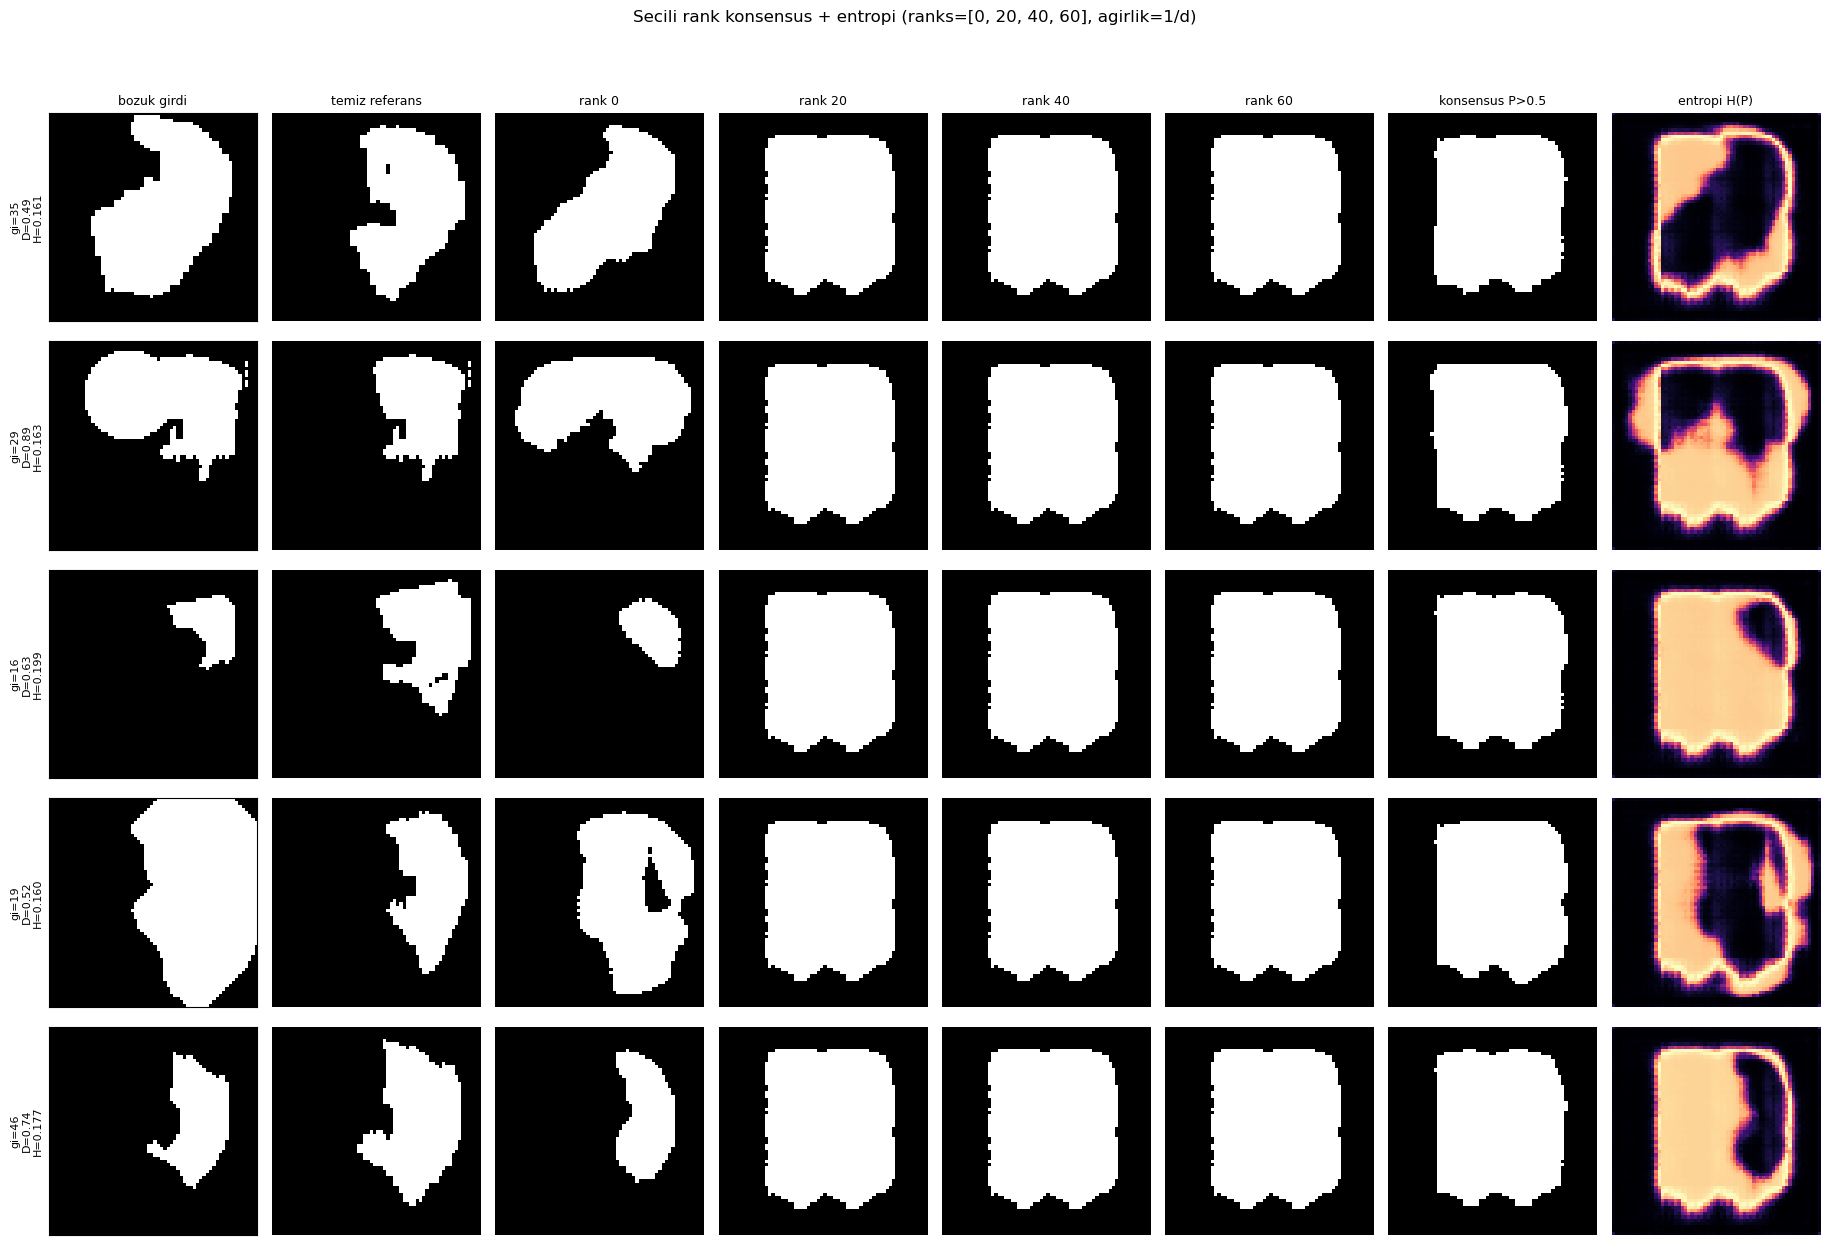

In [17]:
# ---- AYARLAR ----
SEL_RANKS = [0, 20,40,60]      # SECTIGIN adaylar (ilk-5 zorunlu degil; or. [0, 2, 5])
N_ROWS = 5                 # kac RASTGELE karaciger ornegi alt alta
rng = np.random.default_rng(0)
deg_idx = [i for i in range(len(masks)) if not is_clean[i]]
rows = rng.choice(deg_idx, size=min(N_ROWS, len(deg_idx)), replace=False)

umax = float(np.log(2.0))                       # ikili entropi tavani (nat), koyu=emin
cols = 2 + len(SEL_RANKS) + 2                    # input, ref, adaylar, konsensus, entropi
titles = ["bozuk girdi", "temiz referans"] + [f"rank {r}" for r in SEL_RANKS] + ["konsensus P>0.5", "entropi H(P)"]

fig, axes = plt.subplots(len(rows), cols, figsize=(2.3 * cols, 2.5 * len(rows)))
if len(rows) == 1:
    axes = axes[None, :]
for ri, gi_r in enumerate(rows):
    inp_r = masks[gi_r]
    ref_r = masks[(gi_r // block) * block]
    P, ent, pcands, cw = consensus_from_ranks(model, to_x(inp_r), SEL_RANKS)
    zc_r = inp_r.shape[0] // 2
    cons = (P > 0.5).astype(np.float32)
    panels = [inp_r, ref_r] + [(p > 0.5).astype(np.float32) for p in pcands] + [cons, ent]
    cmaps = ["gray", "gray"] + ["gray"] * len(SEL_RANKS) + ["gray", "magma"]
    for ci, (panel, cm) in enumerate(zip(panels, cmaps)):
        ax = axes[ri, ci]
        if ci == cols - 1:                        # entropi paneli sabit olcek
            ax.imshow(panel[zc_r], cmap=cm, vmin=0.0, vmax=umax)
        else:
            ax.imshow(panel[zc_r], cmap=cm)
        if ri == 0:
            ax.set_title(titles[ci], fontsize=9)
        if ci == 0:
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.axis("off")
    axes[ri, 0].set_ylabel(f"gi={gi_r}\nD={true_dice[gi_r]:.2f}\nH={ent.mean():.3f}", fontsize=8)
fig.suptitle(f"Secili rank konsensus + entropi (ranks={SEL_RANKS}, agirlik=1/d)", y=1.0)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.97))
plt.show()

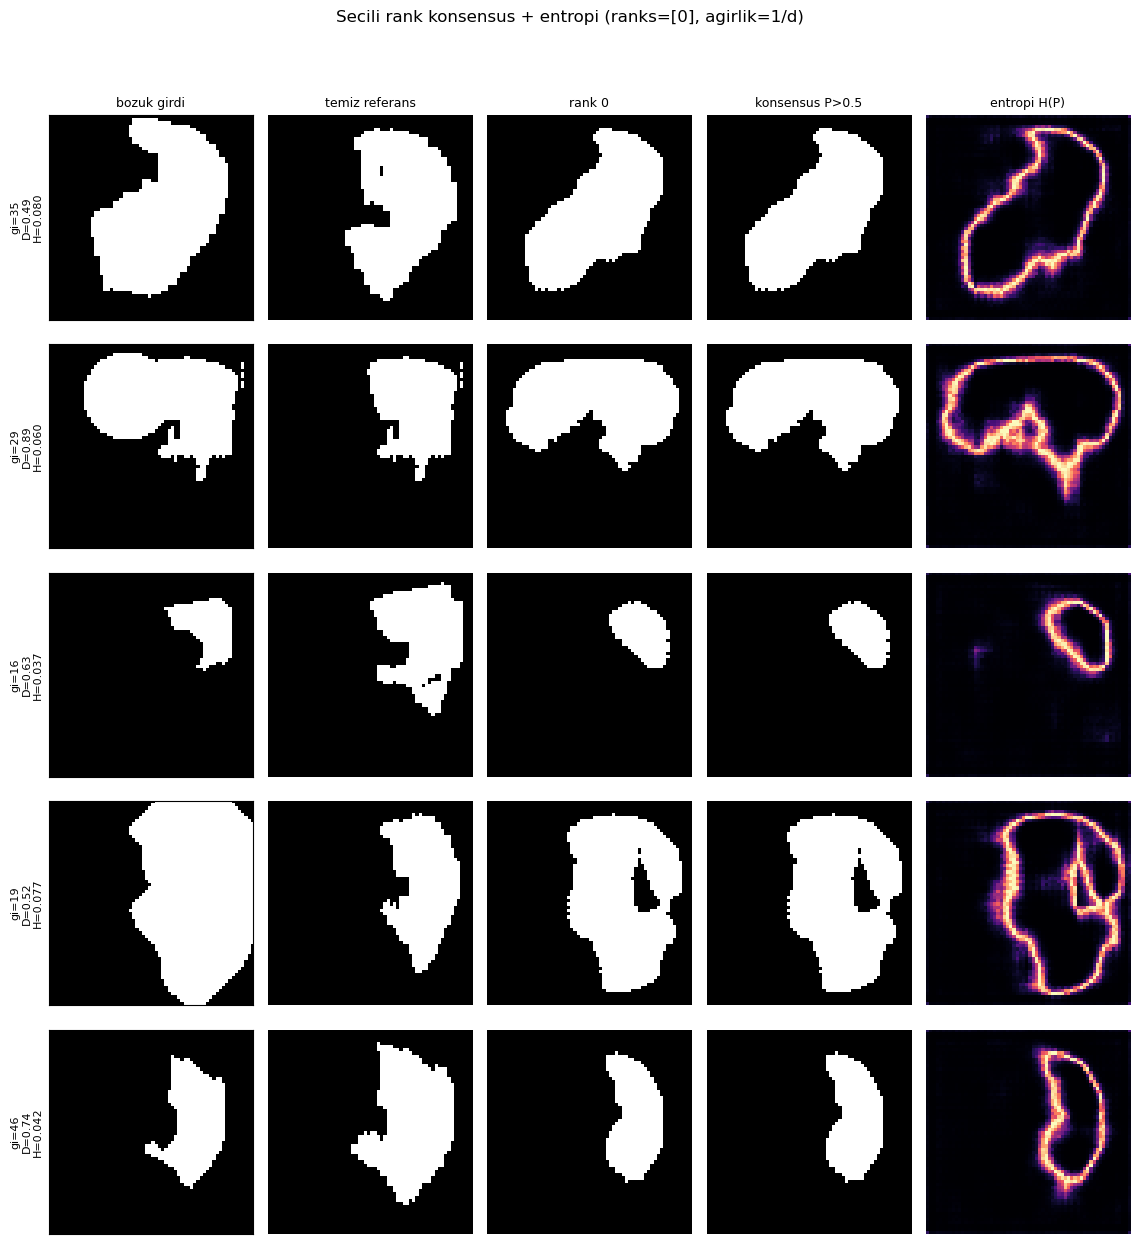

In [18]:
# ---- AYARLAR ----
SEL_RANKS = [0]      # SECTIGIN adaylar (ilk-5 zorunlu degil; or. [0, 2, 5])
N_ROWS = 5                 # kac RASTGELE karaciger ornegi alt alta
rng = np.random.default_rng(0)
deg_idx = [i for i in range(len(masks)) if not is_clean[i]]
rows = rng.choice(deg_idx, size=min(N_ROWS, len(deg_idx)), replace=False)

umax = float(np.log(2.0))                       # ikili entropi tavani (nat), koyu=emin
cols = 2 + len(SEL_RANKS) + 2                    # input, ref, adaylar, konsensus, entropi
titles = ["bozuk girdi", "temiz referans"] + [f"rank {r}" for r in SEL_RANKS] + ["konsensus P>0.5", "entropi H(P)"]

fig, axes = plt.subplots(len(rows), cols, figsize=(2.3 * cols, 2.5 * len(rows)))
if len(rows) == 1:
    axes = axes[None, :]
for ri, gi_r in enumerate(rows):
    inp_r = masks[gi_r]
    ref_r = masks[(gi_r // block) * block]
    P, ent, pcands, cw = consensus_from_ranks(model, to_x(inp_r), SEL_RANKS)
    zc_r = inp_r.shape[0] // 2
    cons = (P > 0.5).astype(np.float32)
    panels = [inp_r, ref_r] + [(p > 0.5).astype(np.float32) for p in pcands] + [cons, ent]
    cmaps = ["gray", "gray"] + ["gray"] * len(SEL_RANKS) + ["gray", "magma"]
    for ci, (panel, cm) in enumerate(zip(panels, cmaps)):
        ax = axes[ri, ci]
        if ci == cols - 1:                        # entropi paneli sabit olcek
            ax.imshow(panel[zc_r], cmap=cm, vmin=0.0, vmax=umax)
        else:
            ax.imshow(panel[zc_r], cmap=cm)
        if ri == 0:
            ax.set_title(titles[ci], fontsize=9)
        if ci == 0:
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.axis("off")
    axes[ri, 0].set_ylabel(f"gi={gi_r}\nD={true_dice[gi_r]:.2f}\nH={ent.mean():.3f}", fontsize=8)
fig.suptitle(f"Secili rank konsensus + entropi (ranks={SEL_RANKS}, agirlik=1/d)", y=1.0)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.97))
plt.show()

## 7) SDF Dice — temiz referans vs SDF tahmini

WP-3 SDF modelini (`vae3d_wp3_sdf_best.pt`) yukler; `reconstruct` = SDF->ikili kopru (`sdf<0 -> ic`). Ayni degradasyon setinde: **temiz referans** ile **SDF tahmini** arasindaki Dice'i olceriz (girdi olarak hem temiz hem bozuk maske).

SDF Dice(temiz girdi tahmini, temiz referans)  = 0.9264
SDF Dice(bozuk girdi tahmini,  temiz referans)  = 0.8687
karsilastirma: bozuk girdinin ham true Dice'i     = 0.8612


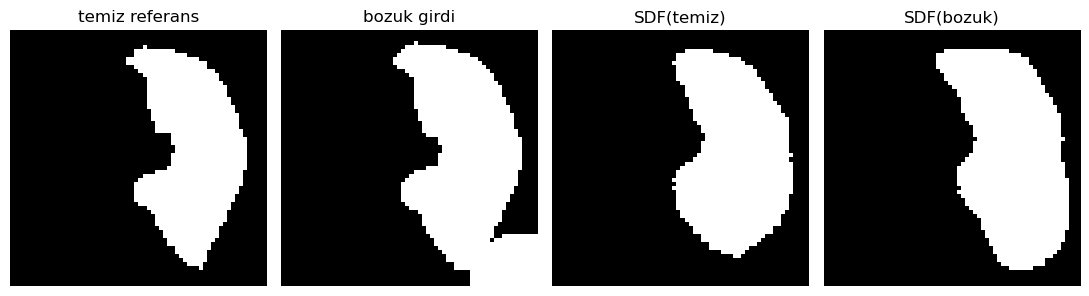

In [16]:
from evaluate_correlation_3d_sdf import load_sdf_model

SDF_CKPT = PROJECT_ROOT / "outputs" / "checkpoints" / "vae3d_wp3_sdf_best.pt"
sdf_model = load_sdf_model(SDF_CKPT, device)
sdf_model.eval()


@torch.no_grad()
def sdf_recon(mask_np):
    rec = sdf_model.reconstruct(to_x(mask_np))     # ikili kopru, (1,1,64,64,64)
    return rec[0, 0].cpu().numpy()


# temiz girdi -> tahmin (model temiz maskeyi ne kadar koruyor?)
rec_clean = sdf_recon(ref)
# bozuk girdi -> tahmin (temiz referansa Dice, WP-3 recon_dice mantigi)
rec_deg = sdf_recon(inp)

print(f"SDF Dice(temiz girdi tahmini, temiz referans)  = {dice(rec_clean, ref):.4f}")
print(f"SDF Dice(bozuk girdi tahmini,  temiz referans)  = {dice(rec_deg, ref):.4f}")
print(f"karsilastirma: bozuk girdinin ham true Dice'i     = {true_dice[gi]:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, img, t in zip(
    axes,
    [ref, inp, rec_clean, rec_deg],
    ["temiz referans", "bozuk girdi", "SDF(temiz)", "SDF(bozuk)"],
):
    ax.imshow(img[zc], cmap="gray"); ax.set_title(t); ax.axis("off")
fig.tight_layout(); plt.show()